<>:50: SyntaxWarning: invalid escape sequence '\o'
<>:50: SyntaxWarning: invalid escape sequence '\o'
/var/folders/kl/39xdwtqn4bddbymh1fznlrh40000gp/T/ipykernel_7832/3376052174.py:50: SyntaxWarning: invalid escape sequence '\o'
  plt.axvline(omega_star, color='red', linestyle='--', label=f'$\omega^* = {omega_star}$')


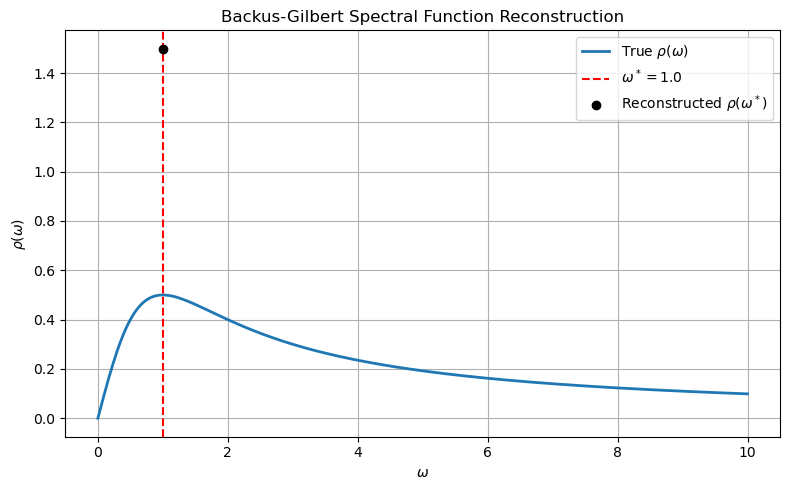

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import inv

# Define spectral function model (toy example)
def model_spectral_function(omega):
    return omega / (1 + omega**2)  # Smooth Lorentzian-like spectrum

# Kernel for finite-temperature Euclidean correlator
def kernel(tau, omega, beta):
    return np.cosh(omega * (tau - beta / 2)) / np.sinh(beta * omega / 2)

# Parameters
beta = 1.0               # Inverse temperature
N_tau = 20               # Number of Euclidean time points
N_omega = 300            # Frequency resolution
omega_max = 10.0         # Max frequency
omega_min = 1e-4         # Avoid division by zero
tau_vals = np.linspace(0, beta, N_tau)
omega_vals = np.linspace(omega_min, omega_max, N_omega)

# Simulate G_E(τ) from model spectral function
G_E = np.zeros(N_tau)
for i, tau in enumerate(tau_vals):
    integrand = model_spectral_function(omega_vals) * kernel(tau, omega_vals, beta)
    G_E[i] = np.trapz(integrand, omega_vals)

# Construct kernel matrix K(ω, τ)
K_matrix = np.array([[kernel(tau, omega, beta) for tau in tau_vals] for omega in omega_vals])

# Compute covariance matrix (using identity as approximation here)
C = np.eye(N_tau) * 1e-6  # Tiny regularization (use real covariance for real data)

# Choose target frequency ω*
omega_star = 1.0
K_star = np.array([kernel(tau, omega_star, beta) for tau in tau_vals])

# Compute Backus-Gilbert weights
invC = inv(C)
numerator = invC @ K_star
denominator = K_star.T @ invC @ K_star
a_weights = numerator / denominator  # shape (N_tau,)

# Estimate spectral function at ω*
rho_est = a_weights @ G_E

# Plot the result
plt.figure(figsize=(8, 5))
plt.plot(omega_vals, model_spectral_function(omega_vals), label='True $\\rho(\\omega)$', lw=2)
plt.axvline(omega_star, color='red', linestyle='--', label=f'$\omega^* = {omega_star}$')
plt.scatter([omega_star], [rho_est], color='black', zorder=10, label='Reconstructed $\\rho(\\omega^*)$')
plt.xlabel(r'$\omega$')
plt.ylabel(r'$\rho(\omega)$')
plt.title('Backus-Gilbert Spectral Function Reconstruction')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


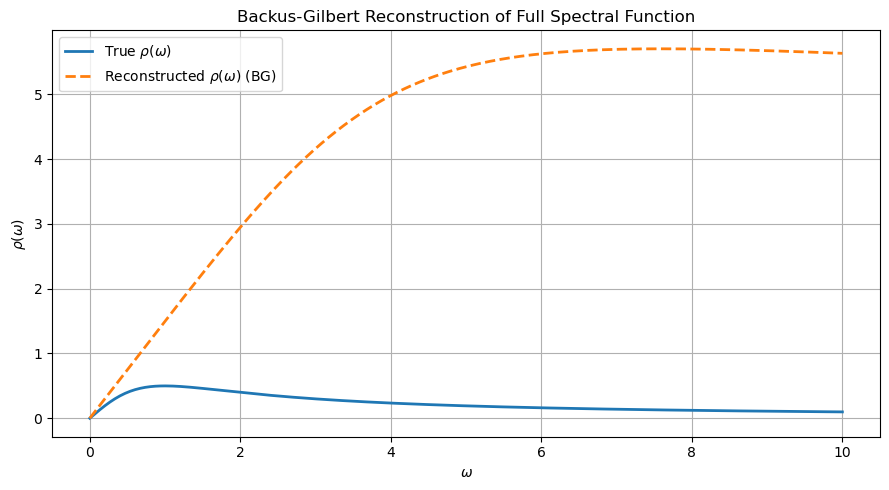

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import inv

# --------------------------
# 1. Model spectral function
# --------------------------
def model_spectral_function(omega):
    return omega / (1 + omega**2)  # Simple, smooth shape

def kernel(tau, omega, beta):
    return np.cosh(omega * (tau - beta / 2)) / np.sinh(beta * omega / 2)

# ------------------------
# 2. Simulation parameters
# ------------------------
beta = 1.0
N_tau = 20
N_omega = 300
omega_min, omega_max = 1e-3, 10.0

tau_vals = np.linspace(0, beta, N_tau)
omega_vals = np.linspace(omega_min, omega_max, N_omega)

# -----------------------------
# 3. Generate synthetic G_E(τ)
# -----------------------------
G_E = np.zeros(N_tau)
for i, tau in enumerate(tau_vals):
    integrand = model_spectral_function(omega_vals) * kernel(tau, omega_vals, beta)
    G_E[i] = np.trapz(integrand, omega_vals)

# ------------------------------------
# 4. Approximate covariance (identity)
# ------------------------------------
C = np.eye(N_tau) * 1e-6  # Regularization to stabilize inversion
invC = inv(C)

# --------------------------------------------------------
# 5. Backus-Gilbert method over all ω* (reconstruction loop)
# --------------------------------------------------------
rho_reconstructed = []

for omega_star in omega_vals:
    K_star = np.array([kernel(tau, omega_star, beta) for tau in tau_vals])  # shape (N_tau,)
    numerator = invC @ K_star
    denominator = K_star.T @ invC @ K_star
    a_weights = numerator / denominator
    rho_est = a_weights @ G_E
    rho_reconstructed.append(rho_est)

rho_reconstructed = np.array(rho_reconstructed)

# ---------------------
# 6. Plotting the result
# ---------------------
plt.figure(figsize=(9, 5))
plt.plot(omega_vals, model_spectral_function(omega_vals), label='True $\\rho(\\omega)$', lw=2)
plt.plot(omega_vals, rho_reconstructed, label='Reconstructed $\\rho(\\omega)$ (BG)', lw=2, linestyle='--')
plt.xlabel(r'$\omega$')
plt.ylabel(r'$\rho(\omega)$')
plt.title('Backus-Gilbert Reconstruction of Full Spectral Function')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
